In [52]:
import pandas as pd
import numpy as np
from sklearn.metrics import f1_score, accuracy_score
import plotnine as nine

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler

In [53]:
df = pd.read_csv('data/31mar2026.tsv', sep='\t', low_memory=False)

In [54]:
# Convert the date column to datetime
df['Time (UTC)'] = pd.to_datetime(df['Time (UTC)'], format='%Y-%m-%d.%H:%M')

In [55]:
features = [
    'Time (UTC)',
    'HREG_T_OP2',
    'HREG_EFFECTIVE_TF',
    'HREG_EFFECTIVE_PF',
    'HREG_T_FRS',
    'HREG_T_SPLY_LTO',
    'HREG_T_SPLY',
    'HREG_T_WST',
    'HREG_T_EXT',
    'HREG_HUM_EXT',
    'HREG_AI1_RES',
    'HREG_AI3_RES',
    'HREG_AI4_RES',
    'HREG_AI5_RES',
    'HREG_AI6_RES',
    'HREG_LTO_N_SPLY',
    'HREG_LTO_N_EXT',
    'HREG_RH_MEAN',
    'HREG_OUTPUT'
]

df = df[features]

In [56]:
df_keep = df.copy()

In [57]:
df.dtypes

Time (UTC)           datetime64[ns]
HREG_T_OP2                   object
HREG_EFFECTIVE_TF            object
HREG_EFFECTIVE_PF            object
HREG_T_FRS                   object
HREG_T_SPLY_LTO              object
HREG_T_SPLY                  object
HREG_T_WST                   object
HREG_T_EXT                   object
HREG_HUM_EXT                 object
HREG_AI1_RES                 object
HREG_AI3_RES                 object
HREG_AI4_RES                 object
HREG_AI5_RES                 object
HREG_AI6_RES                 object
HREG_LTO_N_SPLY              object
HREG_LTO_N_EXT               object
HREG_RH_MEAN                 object
HREG_OUTPUT                  object
dtype: object

In [58]:
df

,Time (UTC),HREG_T_OP2,HREG_EFFECTIVE_TF,HREG_EFFECTIVE_PF,HREG_T_FRS,HREG_T_SPLY_LTO,HREG_T_SPLY,HREG_T_WST,HREG_T_EXT,HREG_HUM_EXT,HREG_AI1_RES,HREG_AI3_RES,HREG_AI4_RES,HREG_AI5_RES,HREG_AI6_RES,HREG_LTO_N_SPLY,HREG_LTO_N_EXT,HREG_RH_MEAN,HREG_OUTPUT
0,2013-05-05 12:47:00,-,-,-,"10,6","18,2","18,8",12,"21,4",27,26,"26,2","59,4",524,2640,70,86,27,58
1,2013-05-05 12:53:00,-,-,-,"10,6","15,9","17,2","13,9","21,4",27,25,22,"59,4",516,2640,49,69,27,2
2,2013-05-05 12:58:00,-,-,-,"10,6","11,7","13,9","18,6","21,3",26,25,"21,9","59,4",503,2640,0,0,27,0
3,2013-05-05 13:03:00,-,-,-,"10,6",11,"13,1","19,1","21,5",26,25,"21,9","59,4",495,2640,0,0,27,0
4,2013-05-05 13:08:00,-,-,-,"10,4","10,7","12,8","19,3","21,5",26,25,"21,9","59,4",490,2640,0,0,27,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1226109,2026-03-31 11:53:00,"21,3",41,45,"10,6","18,3","18,6","12,8","19,7",31,29,0,"22,5",0,470,84,75,40,100
1226110,2026-03-31 11:58:00,"21,3",41,45,"10,5","18,2","18,6","12,8","19,8",31,29,0,"22,5",0,472,83,75,40,100
1226111,2026-03-31 12:03:00,"21,3",41,45,"10,5","18,2","18,5","12,6","19,7",31,28,0,"22,5",0,462,84,76,40,100
1226112,2026-03-31 12:08:00,"21,3",41,45,"10,2","18,1","18,6","12,5","19,7",31,28,0,"22,6",0,462,83,76,40,100


In [59]:
numeric_cols = [col for col in df.columns if col != 'Time (UTC)']

df[numeric_cols] = df[numeric_cols].apply(lambda x: x.astype(str).str.replace(',', '.', regex=False))
df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors='coerce')

In [60]:
df

,Time (UTC),HREG_T_OP2,HREG_EFFECTIVE_TF,HREG_EFFECTIVE_PF,HREG_T_FRS,HREG_T_SPLY_LTO,HREG_T_SPLY,HREG_T_WST,HREG_T_EXT,HREG_HUM_EXT,HREG_AI1_RES,HREG_AI3_RES,HREG_AI4_RES,HREG_AI5_RES,HREG_AI6_RES,HREG_LTO_N_SPLY,HREG_LTO_N_EXT,HREG_RH_MEAN,HREG_OUTPUT
0,2013-05-05 12:47:00,NaN,NaN,NaN,10.6,18.2,18.8,12.0,21.4,27.0,26.0,26.2,59.4,524.0,2640.0,70.0,86.0,27.0,58.0
1,2013-05-05 12:53:00,NaN,NaN,NaN,10.6,15.9,17.2,13.9,21.4,27.0,25.0,22.0,59.4,516.0,2640.0,49.0,69.0,27.0,2.0
2,2013-05-05 12:58:00,NaN,NaN,NaN,10.6,11.7,13.9,18.6,21.3,26.0,25.0,21.9,59.4,503.0,2640.0,0.0,0.0,27.0,0.0
3,2013-05-05 13:03:00,NaN,NaN,NaN,10.6,11.0,13.1,19.1,21.5,26.0,25.0,21.9,59.4,495.0,2640.0,0.0,0.0,27.0,0.0
4,2013-05-05 13:08:00,NaN,NaN,NaN,10.4,10.7,12.8,19.3,21.5,26.0,25.0,21.9,59.4,490.0,2640.0,0.0,0.0,27.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1226109,2026-03-31 11:53:00,21.3,41.0,45.0,10.6,18.3,18.6,12.8,19.7,31.0,29.0,0.0,22.5,0.0,470.0,84.0,75.0,40.0,100.0
1226110,2026-03-31 11:58:00,21.3,41.0,45.0,10.5,18.2,18.6,12.8,19.8,31.0,29.0,0.0,22.5,0.0,472.0,83.0,75.0,40.0,100.0
1226111,2026-03-31 12:03:00,21.3,41.0,45.0,10.5,18.2,18.5,12.6,19.7,31.0,28.0,0.0,22.5,0.0,462.0,84.0,76.0,40.0,100.0
1226112,2026-03-31 12:08:00,21.3,41.0,45.0,10.2,18.1,18.6,12.5,19.7,31.0,28.0,0.0,22.6,0.0,462.0,83.0,76.0,40.0,100.0


In [61]:
def label_hru(df):
    condition = (
        (df['HREG_OUTPUT'] == 100) &
        (df['HREG_LTO_N_SPLY'] > 80) &
        (df['HREG_LTO_N_EXT'] > 85)
    )
    df['HRU_LABEL'] = condition.apply(lambda x: 0 if x else 1)
    return df

df = label_hru(df)

df = df.dropna()

In [62]:
df['HRU_LABEL'].value_counts()

HRU_LABEL
1    1182121
0        802
Name: count, dtype: int64

In [63]:
df_filtered = df[df['Time (UTC)'].between('2026-03-01', '2026-03-31')]
df_filtered.size
df_filtered.dropna()

,Time (UTC),HREG_T_OP2,HREG_EFFECTIVE_TF,HREG_EFFECTIVE_PF,HREG_T_FRS,HREG_T_SPLY_LTO,HREG_T_SPLY,HREG_T_WST,HREG_T_EXT,HREG_HUM_EXT,HREG_AI1_RES,HREG_AI3_RES,HREG_AI4_RES,HREG_AI5_RES,HREG_AI6_RES,HREG_LTO_N_SPLY,HREG_LTO_N_EXT,HREG_RH_MEAN,HREG_OUTPUT,HRU_LABEL
1217841,2026-03-01 00:00:00,21.0,41.0,45.0,0.7,15.5,15.8,4.7,18.6,26.0,23.0,0.0,21.6,0.0,397.0,82.0,77.0,33.0,100.0,1
1217842,2026-03-01 00:05:00,21.0,41.0,45.0,0.6,15.5,15.8,4.7,18.5,25.0,23.0,0.0,21.5,0.0,395.0,82.0,77.0,33.0,100.0,1
1217843,2026-03-01 00:10:00,21.0,41.0,45.0,0.6,15.4,15.8,4.7,18.4,26.0,23.0,0.0,21.7,0.0,387.0,83.0,77.0,33.0,100.0,1
1217844,2026-03-01 00:15:00,21.0,41.0,45.0,0.6,15.4,15.8,4.7,18.5,26.0,23.0,0.0,21.6,0.0,397.0,82.0,77.0,33.0,100.0,1
1217845,2026-03-01 00:20:00,21.0,41.0,45.0,0.7,15.4,15.8,4.7,18.6,26.0,23.0,0.0,21.6,0.0,392.0,82.0,77.0,33.0,100.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1225963,2026-03-30 23:36:00,21.2,41.0,45.0,2.2,16.1,16.4,6.0,19.3,31.0,27.0,0.0,22.5,0.0,991.0,81.0,77.0,40.0,100.0,1
1225964,2026-03-30 23:41:00,21.3,41.0,45.0,2.2,16.3,16.5,6.0,19.2,31.0,27.0,0.0,22.6,0.0,994.0,83.0,77.0,40.0,100.0,1
1225965,2026-03-30 23:46:00,21.3,41.0,45.0,2.1,16.1,16.5,6.0,19.1,31.0,27.0,0.0,22.5,0.0,994.0,82.0,77.0,40.0,100.0,1
1225966,2026-03-30 23:51:00,21.3,41.0,45.0,2.2,16.1,16.5,6.0,19.3,31.0,27.0,0.0,22.6,0.0,996.0,81.0,77.0,40.0,100.0,1


In [64]:
sampled_df = (
    df.groupby('HRU_LABEL', group_keys=False)
    .apply(lambda x: x.sample(n=500, random_state=42))
    .reset_index(drop=True)
)

/var/folders/pd/90ytb97x315_j_11fnz47nw80000gp/T/ipykernel_24656/2088954968.py:3: DeprecationWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.



In [65]:
X = sampled_df[numeric_cols]
y = sampled_df['HRU_LABEL']

In [66]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

model = DecisionTreeClassifier()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

f1_score(y_test, y_pred)

0.9969604863221885

In [67]:
X

,HREG_T_OP2,HREG_EFFECTIVE_TF,HREG_EFFECTIVE_PF,HREG_T_FRS,HREG_T_SPLY_LTO,HREG_T_SPLY,HREG_T_WST,HREG_T_EXT,HREG_HUM_EXT,HREG_AI1_RES,HREG_AI3_RES,HREG_AI4_RES,HREG_AI5_RES,HREG_AI6_RES,HREG_LTO_N_SPLY,HREG_LTO_N_EXT,HREG_RH_MEAN,HREG_OUTPUT
0,20.9,41.0,45.0,19.1,19.8,20.3,19.1,19.5,57.0,56.0,0.0,21.5,0.0,426.0,100.0,100.0,64.0,100.0
1,20.1,41.0,45.0,16.4,18.4,18.9,16.7,18.4,58.0,57.0,0.0,21.0,0.0,413.0,100.0,86.0,61.0,100.0
2,20.8,41.0,45.0,18.5,19.6,20.1,18.6,19.6,53.0,50.0,0.0,21.1,0.0,413.0,100.0,86.0,65.0,100.0
3,22.0,41.0,45.0,18.1,19.7,20.2,18.2,19.9,44.0,45.0,0.0,23.2,0.0,472.0,88.0,96.0,54.0,100.0
4,21.7,41.0,45.0,18.1,19.6,20.0,18.3,19.6,43.0,42.0,0.0,22.8,0.0,426.0,100.0,89.0,54.0,100.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,21.2,0.0,20.0,5.6,7.3,9.4,15.9,19.2,28.0,27.0,25.8,21.3,952.0,10.0,11.0,24.0,29.0,0.0
996,21.5,41.0,45.0,4.6,17.1,17.3,8.2,18.9,32.0,29.0,0.0,22.2,0.0,493.0,87.0,74.0,34.0,100.0
997,21.2,40.0,40.0,2.6,16.2,16.6,6.2,19.1,31.0,32.0,21.5,22.2,630.0,5.0,82.0,78.0,42.0,100.0
998,23.2,41.0,45.0,19.7,19.8,20.5,20.6,21.1,27.0,25.0,0.0,24.3,0.0,423.0,0.0,0.0,35.0,0.0


In [68]:
## removing the three columns we used to make the column
X = X.drop(['HREG_LTO_N_SPLY','HREG_LTO_N_EXT', 'HREG_OUTPUT'], axis=1)

In [69]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

model = DecisionTreeClassifier()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

f1_score(y_test, y_pred)

0.9631901840490797

In [70]:
y_test

521    1
737    1
740    1
660    1
411    0
      ..
506    1
342    0
485    0
711    1
133    0
Name: HRU_LABEL, Length: 330, dtype: int64

In [71]:
from ciu import CIU, ciuplots

In [72]:
# For label 0
idx_0 = sampled_df[sampled_df['HRU_LABEL'] == 0].sample(n=1, random_state=42).index[0]

# For label 1
idx_1 = sampled_df[sampled_df['HRU_LABEL'] == 1].sample(n=1, random_state=42).index[0]

In [73]:
sampled_df.loc[[521]]

,Time (UTC),HREG_T_OP2,HREG_EFFECTIVE_TF,HREG_EFFECTIVE_PF,HREG_T_FRS,HREG_T_SPLY_LTO,HREG_T_SPLY,HREG_T_WST,HREG_T_EXT,HREG_HUM_EXT,HREG_AI1_RES,HREG_AI3_RES,HREG_AI4_RES,HREG_AI5_RES,HREG_AI6_RES,HREG_LTO_N_SPLY,HREG_LTO_N_EXT,HREG_RH_MEAN,HREG_OUTPUT,HRU_LABEL
521,2017-11-12 02:02:00,21.9,43.0,49.0,3.3,16.6,17.0,6.8,19.3,38.0,34.0,21.9,21.9,1053.0,785.0,83.0,77.0,40.0,100.0,1


In [74]:
CIU_hru = CIU(model.predict_proba, ['No','Yes'], data = X_train)
CIU_hru.instance

# Use .loc to retrieve by label index
instance_1 = X_test.loc[[521]] #Has fault
instance_2 = X_test.loc[[411]] #Has no fault

print(model.predict_proba(instance_1))
print(model.predict_proba(instance_2))

[[0. 1.]]
[[1. 0.]]


,CI,CU,Cinfl,outname,outval,feature,ymin,ymax,inputs,invals,neutralCU,target_concept,target_inputs
HREG_T_OP2,0.0,0,-0.0,Yes,1.0,HREG_T_OP2,1.0,1.0,[0],[21.9],0.5,None,None
HREG_EFFECTIVE_TF,0.0,0,-0.0,Yes,1.0,HREG_EFFECTIVE_TF,1.0,1.0,[1],[43.0],0.5,None,None
HREG_EFFECTIVE_PF,0.0,0,-0.0,Yes,1.0,HREG_EFFECTIVE_PF,1.0,1.0,[2],[49.0],0.5,None,None
HREG_T_FRS,0.0,0,-0.0,Yes,1.0,HREG_T_FRS,1.0,1.0,[3],[3.3],0.5,None,None
HREG_T_SPLY_LTO,0.0,0,-0.0,Yes,1.0,HREG_T_SPLY_LTO,1.0,1.0,[4],[16.6],0.5,None,None
HREG_T_SPLY,0.0,0,-0.0,Yes,1.0,HREG_T_SPLY,1.0,1.0,[5],[17.0],0.5,None,None
HREG_T_WST,0.0,0,-0.0,Yes,1.0,HREG_T_WST,1.0,1.0,[6],[6.8],0.5,None,None
HREG_T_EXT,0.0,0,-0.0,Yes,1.0,HREG_T_EXT,1.0,1.0,[7],[19.3],0.5,None,None
HREG_HUM_EXT,0.0,0,-0.0,Yes,1.0,HREG_HUM_EXT,1.0,1.0,[8],[38.0],0.5,None,None
HREG_AI1_RES,0.0,0,-0.0,Yes,1.0,HREG_AI1_RES,1.0,1.0,[9],[34.0],0.5,None,None


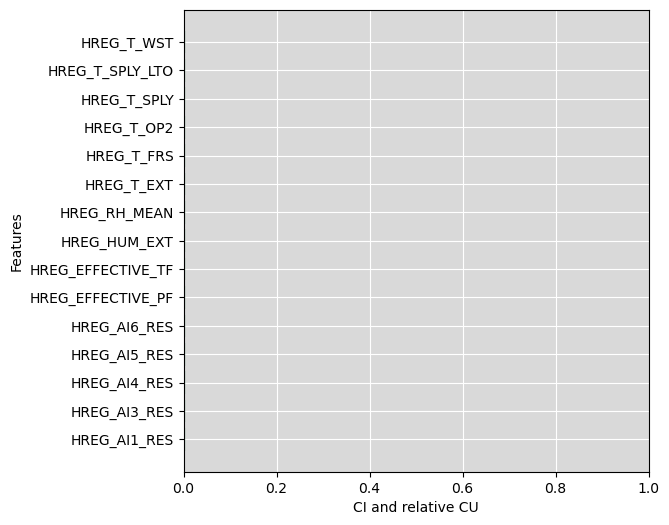

In [75]:
CIUres_1 = CIU_hru.explain(instance_1, output_inds=1)
display(CIUres_1)

p = CIU_hru.plot_ciu(CIUres_1, plot_mode="overlap", figsize=(6,6))

,CI,CU,Cinfl,outname,outval,feature,ymin,ymax,inputs,invals,neutralCU,target_concept,target_inputs
HREG_T_OP2,1.0,1.0,0.5,No,1.0,HREG_T_OP2,0.0,1.0,[0],[21.3],0.5,None,None
HREG_EFFECTIVE_TF,0.0,0.0,-0.0,No,1.0,HREG_EFFECTIVE_TF,1.0,1.0,[1],[57.0],0.5,None,None
HREG_EFFECTIVE_PF,0.0,0.0,-0.0,No,1.0,HREG_EFFECTIVE_PF,1.0,1.0,[2],[62.0],0.5,None,None
HREG_T_FRS,1.0,1.0,0.5,No,1.0,HREG_T_FRS,0.0,1.0,[3],[16.6],0.5,None,None
HREG_T_SPLY_LTO,1.0,1.0,0.5,No,1.0,HREG_T_SPLY_LTO,0.0,1.0,[4],[19.4],0.5,None,None
HREG_T_SPLY,0.0,0.0,-0.0,No,1.0,HREG_T_SPLY,1.0,1.0,[5],[19.9],0.5,None,None
HREG_T_WST,0.0,0.0,-0.0,No,1.0,HREG_T_WST,1.0,1.0,[6],[16.8],0.5,None,None
HREG_T_EXT,1.0,1.0,0.5,No,1.0,HREG_T_EXT,0.0,1.0,[7],[19.8],0.5,None,None
HREG_HUM_EXT,0.0,0.0,-0.0,No,1.0,HREG_HUM_EXT,1.0,1.0,[8],[62.0],0.5,None,None
HREG_AI1_RES,0.0,0.0,-0.0,No,1.0,HREG_AI1_RES,1.0,1.0,[9],[61.0],0.5,None,None


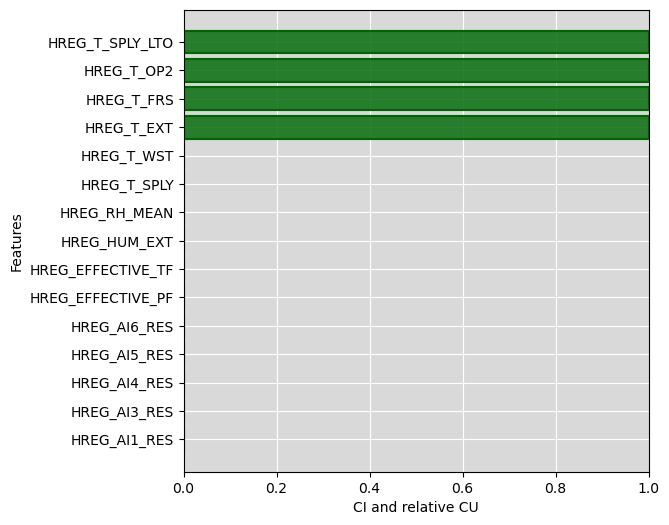

In [76]:
CIUres_2 = CIU_hru.explain(instance_2, output_inds=0)
display(CIUres_2)

p = CIU_hru.plot_ciu(CIUres_2, plot_mode="overlap", figsize=(6,6))

In [77]:
CIUres = CIU_hru.explain_all(X_test, output_inds=1, do_norm_invals=True)

In [78]:
display(CIUres)

,CI,CU,Cinfl,outname,outval,feature,ymin,ymax,inputs,invals,neutralCU,target_concept,target_inputs,instance_name,norm_invals
0,0.0,0.0,-0.0,Yes,1.0,HREG_T_OP2,1.0,1.0,[0],[21.9],0.5,None,None,521,0.333333
1,0.0,0.0,-0.0,Yes,1.0,HREG_EFFECTIVE_TF,1.0,1.0,[1],[43.0],0.5,None,None,521,0.43
2,0.0,0.0,-0.0,Yes,1.0,HREG_EFFECTIVE_PF,1.0,1.0,[2],[49.0],0.5,None,None,521,0.3625
3,0.0,0.0,-0.0,Yes,1.0,HREG_T_FRS,1.0,1.0,[3],[3.3],0.5,None,None,521,0.484725
4,0.0,0.0,-0.0,Yes,1.0,HREG_T_SPLY_LTO,1.0,1.0,[4],[16.6],0.5,None,None,521,0.495798
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4945,0.0,0.0,-0.0,Yes,0.0,HREG_AI3_RES,0.0,0.0,[10],[0.0],0.5,None,None,133,0.0
4946,0.0,0.0,-0.0,Yes,0.0,HREG_AI4_RES,0.0,0.0,[11],[23.6],0.5,None,None,133,0.595238
4947,0.0,0.0,-0.0,Yes,0.0,HREG_AI5_RES,0.0,0.0,[12],[0.0],0.5,None,None,133,0.0
4948,0.0,0.0,-0.0,Yes,0.0,HREG_AI6_RES,0.0,0.0,[13],[1004.0],0.5,None,None,133,0.829046


In [79]:
fig = ciuplots.ciu_beeswarm(CIUres,xcol='Cinfl',  legend_title='Value scale')
fig.update_layout(height=600, width=900, margin=dict(l=20, r=20, t=50, b=20))
fig.update_layout(
    title='CInfl versus input value for all features',
    xaxis=dict(title='Contextual Influence (CInf)'),
    yaxis=dict(title='Feature'),
)
fig.show()

In [80]:
fig = ciuplots.ciu_beeswarm(CIUres,  legend_title='Value scale')
fig.update_layout(height=600, width=900, margin=dict(l=20, r=20, t=50, b=20))
fig.update_layout(
    title='CI versus input value for all features',
    xaxis=dict(title='Contextual Importance (CI)'),
    yaxis=dict(title='Feature'),
)
fig.show()

In [81]:
fig = ciuplots.ciu_beeswarm(CIUres, legend_title='Value scale')
fig.update_layout(height=600, width=900, margin=dict(l=20, r=20, t=50, b=20))
fig.update_layout(
    title='CI versus input value for all features',
    xaxis=dict(title='Contextual Importance (CI)'),
    yaxis=dict(title='Feature'),
)
fig.show()

In [82]:
fig = ciuplots.ciu_beeswarm(CIUres, xcol='CU', legend_title='Value scale')
fig.update_layout(height=600, width=900, margin=dict(l=20, r=20, t=20, b=20), xaxis=dict(title='Contextual Utility (CU)'))
fig.show()

In [83]:
from ciu.CIU import contrastive_ciu

In [84]:

contrastive = contrastive_ciu(CIUres_1, CIUres_2)
display(contrastive)

HREG_T_OP2          -0.0
HREG_EFFECTIVE_TF    0.0
HREG_EFFECTIVE_PF    0.0
HREG_T_FRS          -0.0
HREG_T_SPLY_LTO     -0.0
HREG_T_SPLY          0.0
HREG_T_WST           0.0
HREG_T_EXT          -0.0
HREG_HUM_EXT         0.0
HREG_AI1_RES         0.0
HREG_AI3_RES         0.0
HREG_AI4_RES         0.0
HREG_AI5_RES         0.0
HREG_AI6_RES         0.0
HREG_RH_MEAN         0.0
dtype: float64

In [85]:
# Intermediate Concepts

In [86]:
ahu_voc = {
    "supply_air":['HREG_T_SPLY_LTO', 'HREG_T_SPLY', 'HREG_T_WST','HREG_T_EXT','HREG_T_FRS', 'HREG_T_OP2'],
    "fan_speed":['HREG_EFFECTIVE_TF','HREG_EFFECTIVE_PF'],
    "humidity":['HREG_HUM_EXT','HREG_AI1_RES','HREG_RH_MEAN'],
    "room_conditions":['HREG_AI3_RES','HREG_AI4_RES','HREG_AI5_RES','HREG_AI6_RES'],
    #"hru_effeciency":['HREG_LTO_N_SPLY','HREG_LTO_N_EXT','HREG_OUTPUT']
}

In [87]:
CIU_hru.vocabulary = ahu_voc

In [88]:
index = instance_1.index.item()
pred_y = y_test.loc[index].item()
pred_y

1

In [89]:
instance_1.columns

Index(['HREG_T_OP2', 'HREG_EFFECTIVE_TF', 'HREG_EFFECTIVE_PF', 'HREG_T_FRS',
       'HREG_T_SPLY_LTO', 'HREG_T_SPLY', 'HREG_T_WST', 'HREG_T_EXT',
       'HREG_HUM_EXT', 'HREG_AI1_RES', 'HREG_AI3_RES', 'HREG_AI4_RES',
       'HREG_AI5_RES', 'HREG_AI6_RES', 'HREG_RH_MEAN'],
      dtype='object')

In [90]:
top_res = CIU_hru.explain_voc(instance_1, output_inds=1, nsamples=1000)
display(top_res)

,CI,CU,Cinfl,outname,outval,feature,ymin,ymax,inputs,invals,neutralCU,target_concept,target_inputs
supply_air,1.0,1.0,0.5,Yes,1.0,supply_air,0.0,1.0,"[4, 5, 6, 7, 3, 0]","[16.6, 17.0, 6.8, 19.3, 3.3, 21.9]",0.5,None,None
fan_speed,0.0,0.0,-0.0,Yes,1.0,fan_speed,1.0,1.0,"[1, 2]","[43.0, 49.0]",0.5,None,None
humidity,0.0,0.0,-0.0,Yes,1.0,humidity,1.0,1.0,"[8, 9, 14]","[38.0, 34.0, 40.0]",0.5,None,None
room_conditions,0.0,0.0,-0.0,Yes,1.0,room_conditions,1.0,1.0,"[10, 11, 12, 13]","[21.9, 21.9, 1053.0, 785.0]",0.5,None,None


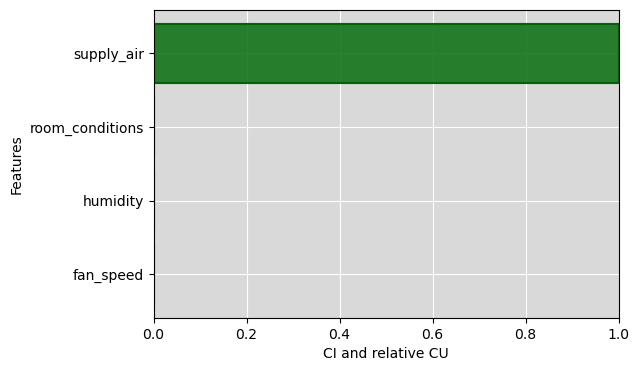

In [91]:
p = CIU_hru.plot_ciu(top_res, plot_mode='overlap')

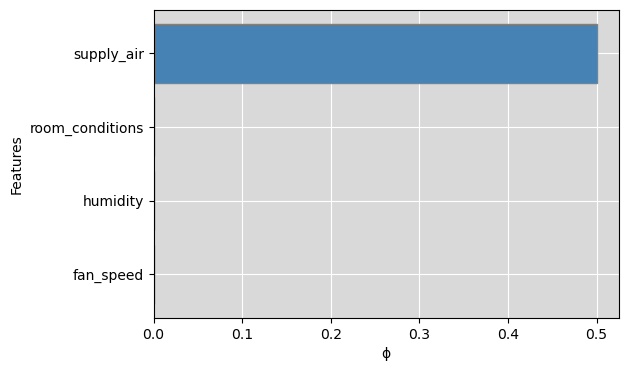

In [92]:
CIU_hru.plot_influence(top_res)

,CI,CU,Cinfl,outname,outval,feature,ymin,ymax,inputs,invals,neutralCU,target_concept,target_inputs
HREG_T_SPLY_LTO,0.0,0,-0.0,Yes,1.0,HREG_T_SPLY_LTO,1.0,1.0,[4],[16.6],0.5,supply_air,"[4, 5, 6, 7, 3, 0]"
HREG_T_SPLY,0.0,0,-0.0,Yes,1.0,HREG_T_SPLY,1.0,1.0,[5],[17.0],0.5,supply_air,"[4, 5, 6, 7, 3, 0]"
HREG_T_WST,0.0,0,-0.0,Yes,1.0,HREG_T_WST,1.0,1.0,[6],[6.8],0.5,supply_air,"[4, 5, 6, 7, 3, 0]"
HREG_T_EXT,0.0,0,-0.0,Yes,1.0,HREG_T_EXT,1.0,1.0,[7],[19.3],0.5,supply_air,"[4, 5, 6, 7, 3, 0]"
HREG_T_FRS,0.0,0,-0.0,Yes,1.0,HREG_T_FRS,1.0,1.0,[3],[3.3],0.5,supply_air,"[4, 5, 6, 7, 3, 0]"
HREG_T_OP2,0.0,0,-0.0,Yes,1.0,HREG_T_OP2,1.0,1.0,[0],[21.9],0.5,supply_air,"[4, 5, 6, 7, 3, 0]"


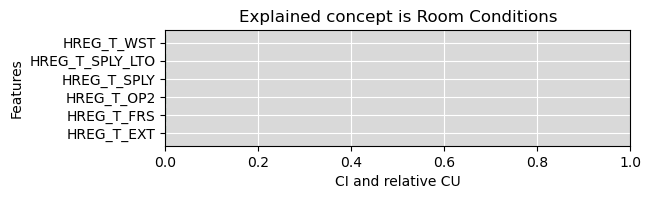

In [ ]:
res =   CIU_hru.explain(instance_1, output_inds=1, target_concept="supply_air", target_ciu=top_res, nsamples=1000)
display(res)
p = CIU_hru.plot_ciu(res, figsize=(6,1.5), plot_mode='overlap', main="Explained concept is Room Conditions")
